In [21]:
# Practia 9. Realizada por Angel Antolin
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.datasets import make_blobs
from sklearn.datasets import make_regression
from sklearn.linear_model import SGDRegressor
from sklearn.model_selection import KFold

# ----------------- EJERCICIO 1---------------------------

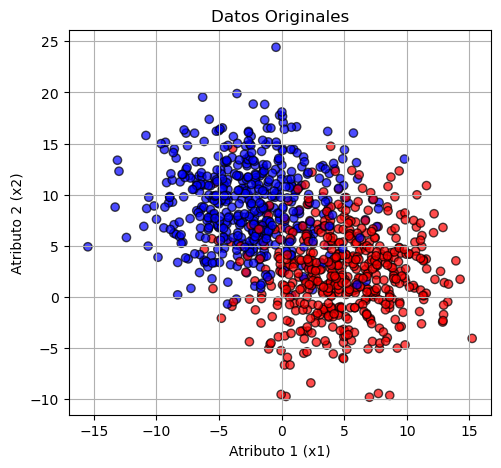

In [22]:
#Generar las 1000 muestras divididas en 2 grupos con 2 atributos

X, Y = make_blobs(n_samples=1000, centers=2, n_features=2, cluster_std=4.0, random_state=42)

#Visualizacion de los datos

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=Y, cmap='bwr', alpha=0.7, edgecolors='k')
plt.title("Datos Originales")
plt.xlabel("Atributo 1 (x1)")
plt.ylabel("Atributo 2 (x2)")
plt.grid(True)

### Añadir unidades a un atributo para poder 

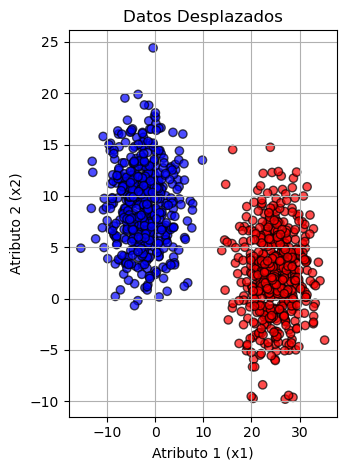

In [24]:
X[Y == 1, 0] += 10  


plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c=Y, cmap='bwr', alpha=0.7, edgecolors='k')
plt.title("Datos Desplazados")
plt.xlabel("Atributo 1 (x1)")
plt.ylabel("Atributo 2 (x2)")
plt.grid(True)

plt.tight_layout()
plt.show()

### Datos separables, creamos la clase Perceptron Simple

In [25]:
class PerceptronSimple:

    #Metodo init para inicializar la neurona y poner los pesos y bias si no se dan
    def __init__(self, n_entradas, W = None, b = None, max_iteraciones = 1000):


        self.n_entradas = n_entradas
        self.max_iteraciones = max_iteraciones

        #Inicializar pesos
        if W is not None:

            self.W = np.array(W, dtype= float)
            
            if len(self.W) != self.n_inputs:
                raise ValueError(f"El tamaño de W ({len(self.W)}) debe coincidir con n_inputs ({self.n_inputs})")
        else:

            # Si no se introduce, se ponen de manera aleatoria
            self.W = np.random.uniform(-0.5, 0.5, self.n_inputs)

        # Inicializar bias
        if b is not None:
            
            self.b = float(b)
        else:
            # Si no se proporciona, se ponen de manera aleatoria
            self.b = np.random.uniform(-0.5, 0.5)

    # Metodo predict para calcular la salida que da la neurona
    def predict (self, X):

        X = np.array(X)

        #Calcular la suma ponderada de la muestra con su peso y sumarle el bias (usar producto escalar para que no importe el formato de entrada)
        suma_ponderada = np.dot(X, self.W) + self.b

        # Funcion de activacion sgn(x), sumas mayores que 0 poner 1, menores poner -1
        salida = np.where(z >= 0, 1, -1)

        return salida

    #Metodo fit aplica el algoritmo de aprendizaje
    def fit (self, X, Y):

        # Bucle de aplicacion del algoritmo
        for iteracion in range(self.max_iter):
            
            #Contamos los errores que encuentra al predecir
            errores = 0

            #Iterar sobre cada X y su valor de clase real
            for xi, clase_real in zip(X, Y):
                
                prediccion = self.predict(xi)
                
                # Si la predicción es incorrecta, se actualizan los pesos 
                if prediccion != clase_real:
                    # Delta W = d(x) * x 
                    self.W += clase_real * xi
                    # El bias se actualiza igual (entrada constante = 1) 
                    self.b += clase_real
                    errores += 1
            
            # Cuando no haya errores, convergencia conseguida 
            if errores == 0:
                print(f"Convergencia alcanzada en la iteracion {iteracion}.")
                return
        
        
        print(f"Error: No se alcanzó la convergencia tras {self.max_iter} iteraciones.")
    
    # Metodo predict_proba calcular probabilidad de pertenencia a una clase
    def predict_proba(self, X):
        
        X = np.array(X)
        
        suma_ponderada = np.dot(X, self.W) + self.b
        
        # Prevención de desbordamiento numérico (overflow) en np.exp
        suma_ponderada_clip = np.clip(suma_ponderada, -250, 250)
        
        # Aplicamos la función Sigmoide para obtener la probabilidad de la clase +1
        prob_clase_positiva = 1 / (1 + np.exp(-suma_ponderada_clip))
        
        # Calculamos la probabilidad complementaria para la clase -1
        prob_clase_negativa = 1 - prob_clase_positiva
        
        # Apilamos los resultados para devolverlos en formato [Prob(-1), Prob(+1)]
        return np.vstack((prob_clase_negativa, prob_clase_positiva)).T

# ---------------------- EJERCICIO 2 ------------------------------

In [26]:

# Creacion de datos sinteticos con los parametros pedidos
X_reg, Y_reg = make_regression(n_samples=1000, n_features=5, noise=5.0, random_state=42)

# Inicializacion del adaline con los parametros pedidos
adaline = SGDRegressor(max_iter=5000, tol=1e-6, random_state=42)

# Metodo para calcular la pseudo_tasa de error en base a un error relativo acotado
def pseudo_tasa(Y_real, Y_pred, tolerancia=0.20):

    
    # Evitamos dividir por cero sumando un valor muy pequeño (epsilon) si y_true es 0
    epsilon = 1e-8
    
    # Calculamos el error relativo para cada muestra: |real - predicho| / |real|
    error_relativo = np.abs(Y_real - Y_pred) / (np.abs(Y_real) + epsilon)
    
    # Computamos como éxito si el error relativo es menor que la cota
    exitos = np.where(error_relativo < tolerancia, 1, 0)
    
    # La tasa es el porcentaje de éxitos sobre el total de muestras
    tasa = np.sum(exitos) / len(Y_real)
    return tasa

### Aplicar Validacion Cruzada

In [30]:
kf = KFold(n_splits=10, shuffle=True, random_state=42)

resultados = []

iteracion = 0

for train_indice, test_indice in kf.split(X_reg):
   
    # Separar datos de entrenamiento y test 
    X_train, X_test = X_reg[train_indice], X_reg[test_indice]
    Y_train, Y_test = Y_reg[train_indice], Y_reg[test_indice]
    
    #Reinstanciar cada bucle para evitar que conserve los pesos
    adaline_cv = SGDRegressor(max_iter=5000, tol=1e-6, random_state=42)
    
    adaline_cv.fit(X_train, Y_train)
    
    # Evaluar el modelo tanto R2 de score como el metodo creado antes
    r2 = adaline_cv.score(X_test, Y_test)
    Y_pred = adaline_cv.predict(X_test)
    accuracy = pseudo_tasa(Y_test, Y_pred, tolerancia=0.20)
    
    # Guardar los datos en nuestra lista
    resultados.append({'Fold': iteracion, 'R2': r2, 'Accuracy': accuracy})
    iteracion += 1


In [33]:
# Mostrar la tabla
df_resultados = pd.DataFrame(resultados).set_index('Fold')
df_resultados = df_resultados.round({'R2': 6, 'Accuracy': 1})
display(df_resultados)

,R2,Accuracy
Fold,,
0,0.994073,0.8
1,0.990286,0.7
2,0.994222,0.8
3,0.992723,0.7
4,0.994128,0.8
5,0.993055,0.7
6,0.995402,0.8
7,0.991740,0.7
8,0.993089,0.8


In [34]:
#Calcular media y desviación estándar
media_r2 = df_resultados['R2'].mean()
std_r2 = df_resultados['R2'].std()

media_acc = df_resultados['Accuracy'].mean()
std_acc = df_resultados['Accuracy'].std()

print("--- Estadísticas Finales ---")
print(f"R2       -> Media: {media_r2:.6f} | Desviación Estándar: {std_r2:.6f}")
print(f"Accuracy -> Media: {media_acc:.6f} | Desviación Estándar: {std_acc:.6f}")

--- Estadísticas Finales ---
R2       -> Media: 0.993328 | Desviación Estándar: 0.001494
Accuracy -> Media: 0.760000 | Desviación Estándar: 0.051640
